# 1.Reduce Model Complexity

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [ ]:
X, y = make_moons(n_samples=500, noise=0.06, random_state=42)

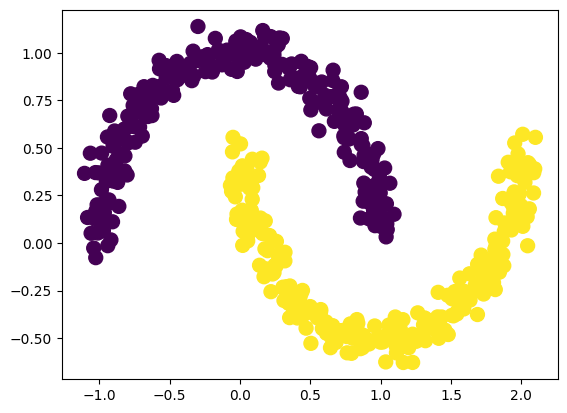

In [ ]:
plt.scatter(X[:,0], X[:,1], c=y, s=100)
plt.show()

In [ ]:
# Reducing the number of hidden layers
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [ ]:
model.get_weights()[0]

array([[-0.19556642, -0.18916786, -0.46660793, -0.01194525, -0.5310029 ,
         0.47527808,  0.6682976 , -0.1869098 ,  0.22908652,  0.32161397],
       [ 0.5915956 ,  0.42807883,  0.44705635, -0.5850861 ,  0.6126221 ,
         0.33621246, -0.49145836,  0.4952814 ,  0.39799827,  0.41432077]],
      dtype=float32)

In [ ]:
old_weights = model.get_weights()[0]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [ ]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4825 - loss: 0.6979   
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4825 - loss: 0.6920 
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5350 - loss: 0.6889 
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7150 - loss: 0.6867 
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5175 - loss: 0.6853 
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5175 - loss: 0.6841 
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5175 - loss: 0.6826 
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5175 - loss: 0.6813 
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5175 - loss: 0.6798 
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5175 - loss: 0.6779 
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5300 - loss: 0.6759  
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/st

In [ ]:
new_weights = model.get_weights()[0]

In [ ]:
model.optimizer.get_config()['learning_rate']

0.0010000000474974513

In [ ]:
gradient = (old_weights - new_weights) / model.optimizer.get_config()['learning_rate']
percent_change = abs(100*(old_weights - new_weights) / old_weights)

In [ ]:
gradient

array([[  151.00345 ,    50.752174,    26.089638,  -218.92212 ,
          -24.520277,   193.54315 ,    89.724594,   -72.67155 ,
         -152.80228 ,  -108.587555],
       [-1223.6971  , -1172.0635  , -1343.9354  ,  1177.1769  ,
        -1226.2439  , -1428.785   ,  1370.2706  , -1035.9237  ,
         1304.2974  ,  1278.0897  ]], dtype=float32)

In [ ]:
percent_change

array([[  77.21339  ,   26.829176 ,    5.591341 , 1832.7131   ,
           4.6177297,   40.72209  ,   13.425845 ,   38.880547 ,
          66.70069  ,   33.76332  ],
       [ 206.84691  ,  273.7962   ,  300.61884  ,  201.19722  ,
         200.16321  ,  424.96494  ,  278.81726  ,  209.15862  ,
         327.71436  ,  308.47833  ]], dtype=float32)

In [ ]:
old_weights

array([[-0.19556642, -0.18916786, -0.46660793, -0.01194525, -0.5310029 ,
         0.47527808,  0.6682976 , -0.1869098 ,  0.22908652,  0.32161397],
       [ 0.5915956 ,  0.42807883,  0.44705635, -0.5850861 ,  0.6126221 ,
         0.33621246, -0.49145836,  0.4952814 ,  0.39799827,  0.41432077]],
      dtype=float32)

In [ ]:
new_weights

array([[-0.34656987, -0.23992004, -0.49269757,  0.20697688, -0.5064826 ,
         0.2817349 ,  0.578573  , -0.11423825,  0.3818888 ,  0.43020153],
       [ 1.8152927 ,  1.6001425 ,  1.7909918 , -1.7622631 ,  1.8388661 ,
         1.7649976 , -1.8617291 ,  1.5312052 , -0.9062991 , -0.863769  ]],
      dtype=float32)

# 2. Using ReLU Activation function

In [ ]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [ ]:
old_weights = model.get_weights()[0]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [ ]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4875 - loss: 0.6926
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8450 - loss: 0.6897 
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8900 - loss: 0.6846 
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9125 - loss: 0.6756 
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9125 - loss: 0.6590 
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9225 - loss: 0.6319 
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9300 - loss: 0.5852 
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9300 - loss: 0.5150 
Epoch 9/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9350 - loss: 0.3991 
Epoch 10/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9425 - loss: 0.2612 
Epoch 11/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9550 - loss: 0.1636 
Epoch 12/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step -

In [ ]:
new_weights = model.get_weights()[0]

In [ ]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [ ]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [ ]:
gradient

array([[  27.755863 ,  122.68888  , -101.1579   ,   31.454353 ,
         175.60446  , -101.61072  ,   71.30331  ,    5.7234836,
        -124.57406  ,  -95.63261  ],
       [ -25.902151 ,  -25.204315 ,  110.98891  ,  -55.890556 ,
        -128.23497  ,  124.59746  , -103.30349  ,  -42.652218 ,
          83.421104 ,  -87.76295  ]], dtype=float32)

In [ ]:
percent_change

array([[34.05309  , 17.532887 , 18.962181 , 14.330126 , 31.370834 ,
        33.057278 , 11.69186  , 10.8817835, 33.59211  , 26.63745  ],
       [ 4.4378486, 12.765671 , 27.016853 , 32.277306 , 29.291485 ,
        33.08836  , 17.10779  , 13.36557  , 50.73205  , 19.482853 ]],
      dtype=float32)

In [ ]:
old_weights

array([[ 0.08150762, -0.6997643 ,  0.5334719 ,  0.2194981 , -0.5597698 ,
         0.30737776,  0.6098543 , -0.05259693,  0.37084323,  0.35901564],
       [ 0.5836646 ,  0.19743824,  0.41081363,  0.17315745,  0.43778926,
        -0.37655982,  0.60383886,  0.3191201 ,  0.16443473,  0.45046252]],
      dtype=float32)

In [ ]:
new_weights

array([[ 0.05375176, -0.8224532 ,  0.6346298 ,  0.18804374, -0.7353743 ,
         0.40898848,  0.538551  , -0.05832041,  0.4954173 ,  0.45464826],
       [ 0.60956675,  0.22264256,  0.2998247 ,  0.22904801,  0.56602424,
        -0.5011573 ,  0.70714235,  0.36177233,  0.08101362,  0.5382255 ]],
      dtype=float32)